# F3 — Prévision de l'inflation

**Nom et prénom :** Aziza Radouani    **Code Apogée :** 25007595    **Groupe :** FIN3    **Filière :** S7 FIN    **Date :** 17/11/2026
**Dépôt GitHub :** https://github.com/aziza-radouani/25007595-aziza-radouani-FIN3

## 1. Sujet et problématique

**Problématique :** le taux de chômage et le taux directeur permettent-ils d’améliorer la prévision de l’inflation annuelle 12 mois à l’avance, par rapport à une prévision simple qui reprend la dernière inflation observée ?

**Objectif :** construire un modèle de prévision avec l’algorithme **Ridge**, puis comparer ses performances à une référence (*baseline*).

**Périmètre :** ce notebook étudie l’inflation des **États-Unis**, car les trois séries utilisées proviennent de FRED (Federal Reserve Bank of St. Louis). Les résultats ne doivent donc pas être interprétés comme des résultats sur l’inflation marocaine.

**Méthode :**
1. Télécharger et préparer les données mensuelles.
2. Explorer l’évolution de l’inflation, du chômage et du taux directeur.
3. Construire une cible correspondant à l’inflation 12 mois après la date de prévision.
4. Entraîner un modèle Ridge avec une séparation chronologique des données.
5. Comparer Ridge au baseline avec MAE et RMSE.
6. Interpréter les résultats et exporter les prédictions.

## 2. Installation et importation des bibliothèques

Exécuter cette cellule en premier. Elle installe la bibliothèque qui permet de télécharger les séries FRED.

In [1]:
!pip -q install pandas-datareader

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas_datareader import data as pdr
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 5)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 3. Collecte des données

Les données sont téléchargées depuis **FRED** :

- `CPIAUCSL` : indice des prix à la consommation (CPI).
- `UNRATE` : taux de chômage (%).
- `FEDFUNDS` : taux effectif des fonds fédéraux (%), utilisé ici comme indicateur du taux directeur.

Les séries ne commencent pas toutes à la même date. La période commune commence donc lorsque les trois variables sont disponibles.

In [3]:
# Télécharger les séries mensuelles depuis FRED
cpi = pdr.DataReader("CPIAUCSL", "fred", start="1947-01-01")
chomage = pdr.DataReader("UNRATE", "fred", start="1948-01-01")
taux = pdr.DataReader("FEDFUNDS", "fred", start="1954-07-01")

df = pd.concat([cpi, chomage, taux], axis=1)
df.columns = ["cpi", "chomage", "taux_directeur"]
df = df.sort_index()

# Inflation annuelle : variation du CPI sur 12 mois, en pourcentage
df["inflation"] = df["cpi"].pct_change(periods=12) * 100

# Conserver les mois pour lesquels les trois séries et l'inflation sont disponibles
df = df.dropna().copy()

print("Nombre d'observations :", len(df))
print("Première date :", df.index.min().strftime("%Y-%m"))
print("Dernière date :", df.index.max().strftime("%Y-%m"))
print("\nValeurs manquantes :")
print(df.isna().sum())
display(df.head())
display(df.tail())

Nombre d'observations : 867
Première date : 1954-07
Dernière date : 2026-10

Valeurs manquantes :
cpi               0
chomage           0
taux_directeur    0
inflation         0
dtype: int64


,cpi,chomage,taux_directeur,inflation
DATE,,,,
1954-07-01,26.86,5.8,0.80,0.261292
1954-08-01,26.85,6.0,1.22,0.000000
1954-09-01,26.81,6.1,1.07,-0.297508
1954-10-01,26.72,5.7,0.85,-0.853432
1954-11-01,26.78,5.3,0.83,-0.260708


,cpi,chomage,taux_directeur,inflation
DATE,,,,
2026-06-01,332.568,4.2,3.63,3.463531
2026-07-01,332.813,4.1,3.63,3.303856
2026-08-01,334.131,4.1,3.63,3.353016
2026-09-01,336.298,4.2,3.75,3.717251
2026-10-01,337.476,4.1,3.88,4.080556


## 4. Compréhension et exploration des données

In [4]:
display(df.describe().round(2))
print("Nombre de lignes dupliquées :", df.index.duplicated().sum())
print("\nTypes des variables :")
print(df.dtypes)

,cpi,chomage,taux_directeur,inflation
count,867.00,867.00,867.00,867.00
mean,136.52,5.79,4.59,3.57
std,89.55,1.67,3.53,2.76
min,26.71,3.40,0.05,-1.96
25%,41.85,4.40,1.94,1.73
50%,131.60,5.50,4.25,2.94
75%,213.09,6.85,6.11,4.37
max,337.48,14.80,19.10,14.59


Nombre de lignes dupliquées : 0

Types des variables :
cpi               float64
chomage           float64
taux_directeur    float64
inflation         float64
dtype: object


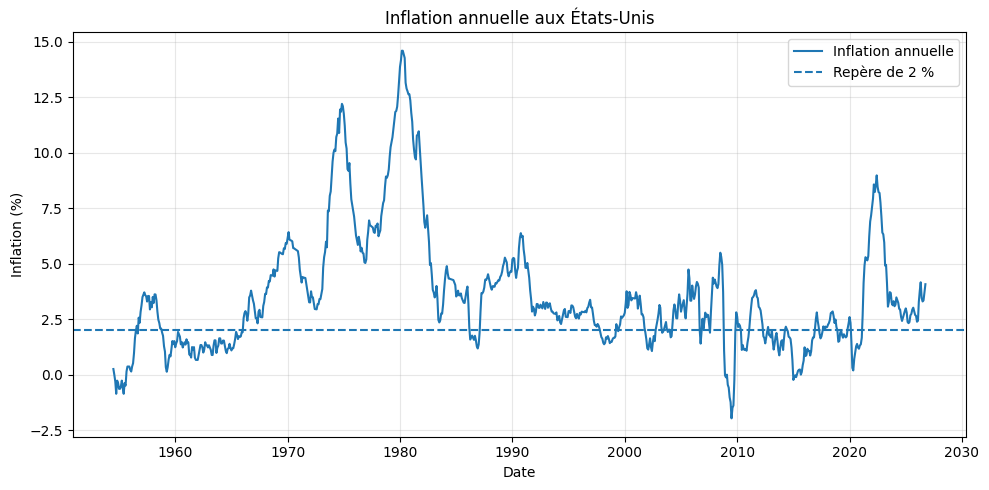

In [5]:
# Évolution de l'inflation annuelle
plt.figure()
plt.plot(df.index, df["inflation"], label="Inflation annuelle")
plt.axhline(2, linestyle="--", label="Repère de 2 %")
plt.title("Inflation annuelle aux États-Unis")
plt.xlabel("Date")
plt.ylabel("Inflation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

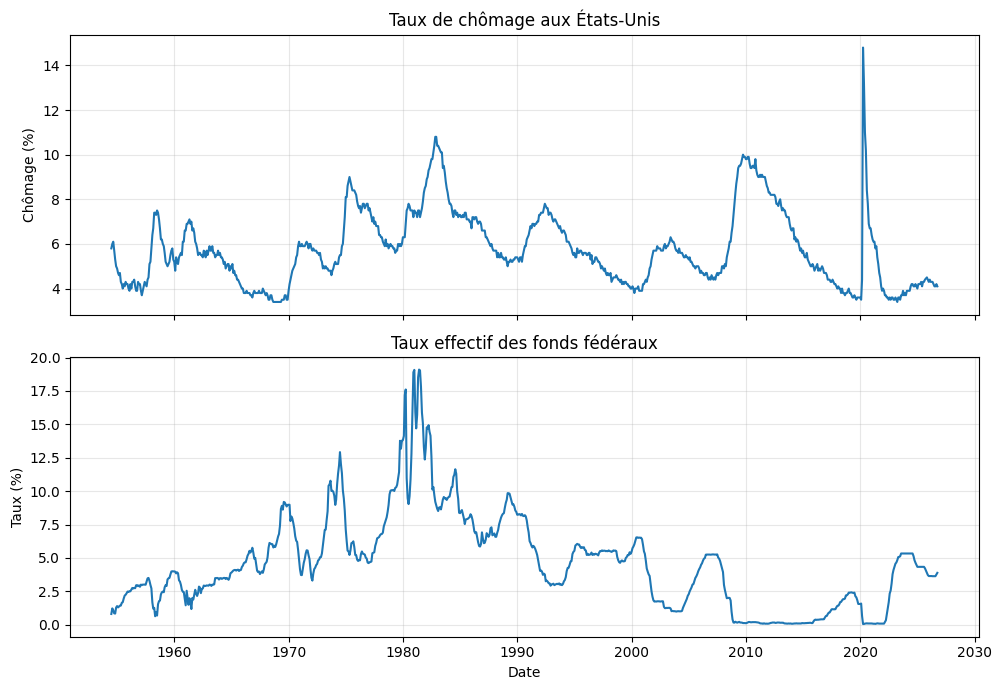

In [6]:
# Évolution du chômage et du taux directeur
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

ax[0].plot(df.index, df["chomage"])
ax[0].set_title("Taux de chômage aux États-Unis")
ax[0].set_ylabel("Chômage (%)")
ax[0].grid(alpha=0.3)

ax[1].plot(df.index, df["taux_directeur"])
ax[1].set_title("Taux effectif des fonds fédéraux")
ax[1].set_ylabel("Taux (%)")
ax[1].set_xlabel("Date")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,inflation,chomage,taux_directeur
inflation,1.00,0.10,0.71
chomage,0.10,1.00,0.07
taux_directeur,0.71,0.07,1.00


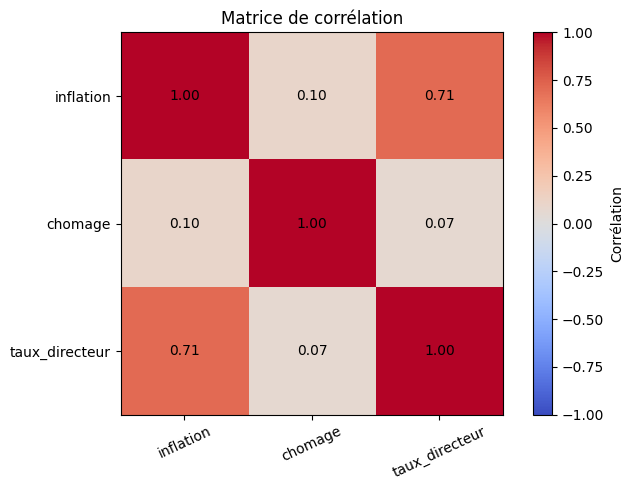

In [7]:
# Matrice de corrélation descriptive
correlations = df[["inflation", "chomage", "taux_directeur"]].corr()
display(correlations.round(2))

plt.figure(figsize=(7, 5))
plt.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations.columns)), correlations.columns, rotation=25)
plt.yticks(range(len(correlations.index)), correlations.index)
for i in range(len(correlations.index)):
    for j in range(len(correlations.columns)):
        plt.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center")
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

### Première lecture des données

Les graphiques et la matrice permettent de décrire les évolutions et les associations entre les variables. Une corrélation ne prouve pas qu’une variable cause l’évolution de l’autre. En particulier, le taux directeur peut aussi réagir à l’inflation déjà observée.

## 5. Préparation de la prévision à 12 mois

Pour chaque mois **t**, le modèle doit prévoir l’inflation du mois **t + 12**.

- **Cible :** `inflation_futur`, égale à l’inflation décalée de 12 mois vers le passé dans le tableau (elle représente donc l’inflation 12 mois après t).
- **Variables explicatives :** inflation observée à t et ses retards, ainsi que chômage et taux directeur retardés d’un mois.
- Les variables explicatives sont donc basées sur des observations passées ou disponibles à la date de prévision.
- Les lignes incomplètes sont supprimées après la création des décalages.

In [8]:
# Créer les variables explicatives à la date de prévision t
model_data = pd.DataFrame(index=df.index)

model_data["inflation_t"] = df["inflation"]
model_data["inflation_lag1"] = df["inflation"].shift(1)
model_data["inflation_lag3"] = df["inflation"].shift(3)
model_data["inflation_lag6"] = df["inflation"].shift(6)
model_data["inflation_lag12"] = df["inflation"].shift(12)

# Retard d'un mois pour tenir compte du délai de publication des indicateurs
model_data["chomage_lag1"] = df["chomage"].shift(1)
model_data["taux_directeur_lag1"] = df["taux_directeur"].shift(1)

# La cible correspond à l'inflation observée 12 mois après la date t
model_data["cible_inflation_t_plus_12"] = df["inflation"].shift(-12)

# Date à laquelle la cible sera observée
model_data["date_cible"] = model_data.index + pd.DateOffset(months=12)

model_data = model_data.dropna().copy()

features = [
    "inflation_t",
    "inflation_lag1",
    "inflation_lag3",
    "inflation_lag6",
    "inflation_lag12",
    "chomage_lag1",
    "taux_directeur_lag1"
]

X = model_data[features]
y = model_data["cible_inflation_t_plus_12"]

print("Dimensions de X :", X.shape)
print("Nombre de valeurs de y :", len(y))
print("Période des dates de prévision :", X.index.min().strftime("%Y-%m"), "à", X.index.max().strftime("%Y-%m"))
display(model_data[features + ["cible_inflation_t_plus_12", "date_cible"]].head())

Dimensions de X : (843, 7)
Nombre de valeurs de y : 843
Période des dates de prévision : 1955-07 à 2025-09


,inflation_t,inflation_lag1,inflation_lag3,inflation_lag6,inflation_lag12,chomage_lag1,taux_directeur_lag1,cible_inflation_t_plus_12,date_cible
DATE,,,,,,,,,
1955-07-01,-0.372301,-0.853749,-0.260611,-0.631032,0.261292,4.2,1.64,1.980568,1956-07-01
1955-08-01,-0.484171,-0.372301,-0.594133,-0.629863,0.000000,4.0,1.68,2.208084,1956-08-01
1955-09-01,0.149198,-0.484171,-0.853749,-0.519866,-0.297508,4.2,1.96,1.862197,1956-09-01
1955-10-01,0.374251,0.149198,-0.372301,-0.260611,-0.853432,4.1,2.18,2.572707,1956-10-01
1955-11-01,0.373413,0.374251,-0.484171,-0.594133,-0.260708,4.3,2.24,2.343750,1956-11-01


## 6. Séparation chronologique entraînement / test

Les données ne sont pas mélangées aléatoirement : l’entraînement utilise les périodes les plus anciennes et le test les périodes les plus récentes.

Pour éviter qu’une cible d’entraînement se situe dans la période de test, on retire aussi de l’entraînement les observations dont la date cible atteint ou dépasse le début du test.

In [9]:
# Début de la période de test : les 20 % de dates de prévision les plus récentes
split_position = int(len(model_data) * 0.80)
date_debut_test = model_data.index[split_position]

# Entraînement : la date à laquelle la cible est observée doit précéder le test
train_mask = model_data["date_cible"] < date_debut_test
test_mask = model_data.index >= date_debut_test

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]
X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

print("Début du test :", date_debut_test.strftime("%Y-%m"))
print("Observations d'entraînement :", len(X_train))
print("Observations de test :", len(X_test))
print("Période d'entraînement :", X_train.index.min().strftime("%Y-%m"), "à", X_train.index.max().strftime("%Y-%m"))
print("Période de test :", X_test.index.min().strftime("%Y-%m"), "à", X_test.index.max().strftime("%Y-%m"))

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Pas assez de données pour effectuer la séparation entraînement/test.")

Début du test : 2011-09
Observations d'entraînement : 662
Observations de test : 169
Période d'entraînement : 1955-07 à 2010-08
Période de test : 2011-09 à 2025-09


## 7. Entraînement du modèle Ridge

Ridge est une régression linéaire régularisée. La standardisation est intégrée dans un pipeline et est ajustée uniquement sur les données d’entraînement.

In [10]:
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Modèle Ridge entraîné avec succès.")
print("Nombre de prédictions :", len(y_pred))

Modèle Ridge entraîné avec succès.
Nombre de prédictions : 169


## 8. Modèle de référence (baseline)

Le baseline est une prévision simple : pour prévoir l’inflation dans 12 mois, on suppose qu’elle restera égale à la dernière inflation connue à la date t.

On compare donc `inflation_t` à la cible réelle `inflation_t_plus_12`.

In [11]:
# Baseline : dernière inflation connue à la date de prévision
y_baseline = model_data.loc[X_test.index, "inflation_t"]

# Vérifier l'alignement des index
assert y_test.index.equals(y_baseline.index)

print("Baseline calculé :", len(y_baseline), "prévisions")

Baseline calculé : 169 prévisions


## 9. Évaluation et comparaison des performances

- **MAE** : erreur absolue moyenne, en points de pourcentage.
- **RMSE** : racine de l’erreur quadratique moyenne ; elle pénalise davantage les grandes erreurs.
- **R²** : mesure la part de la variabilité expliquée par le modèle (elle peut être négative sur le test).

L’objectif de réduction de 10 % du RMSE est évalué à partir des résultats réellement obtenus ; il ne faut pas supposer qu’il est atteint.

In [12]:
def calculer_metriques(y_reel, y_estime):
    return {
        "MAE": mean_absolute_error(y_reel, y_estime),
        "RMSE": np.sqrt(mean_squared_error(y_reel, y_estime)),
        "R2": r2_score(y_reel, y_estime)
    }

metriques_ridge = calculer_metriques(y_test, y_pred)
metriques_baseline = calculer_metriques(y_test, y_baseline)

comparaison = pd.DataFrame(
    [metriques_baseline, metriques_ridge],
    index=["Baseline", "Ridge"]
)

display(comparaison.round(4))

reduction_rmse = (1 - metriques_ridge["RMSE"] / metriques_baseline["RMSE"]) * 100
print(f"Réduction du RMSE de Ridge par rapport au baseline : {reduction_rmse:.2f} %")

if reduction_rmse >= 10:
    print("Objectif atteint : le RMSE de Ridge est inférieur d'au moins 10 % au baseline.")
elif reduction_rmse > 0:
    print("Ridge améliore le baseline, mais l'amélioration est inférieure à 10 %.")
else:
    print("Objectif non atteint : Ridge ne fait pas mieux que le baseline sur le RMSE.")

,MAE,RMSE,R2
Baseline,1.4658,2.0798,-0.0897
Ridge,1.3841,1.9241,0.0674


Réduction du RMSE de Ridge par rapport au baseline : 7.49 %
Ridge améliore le baseline, mais l'amélioration est inférieure à 10 %.


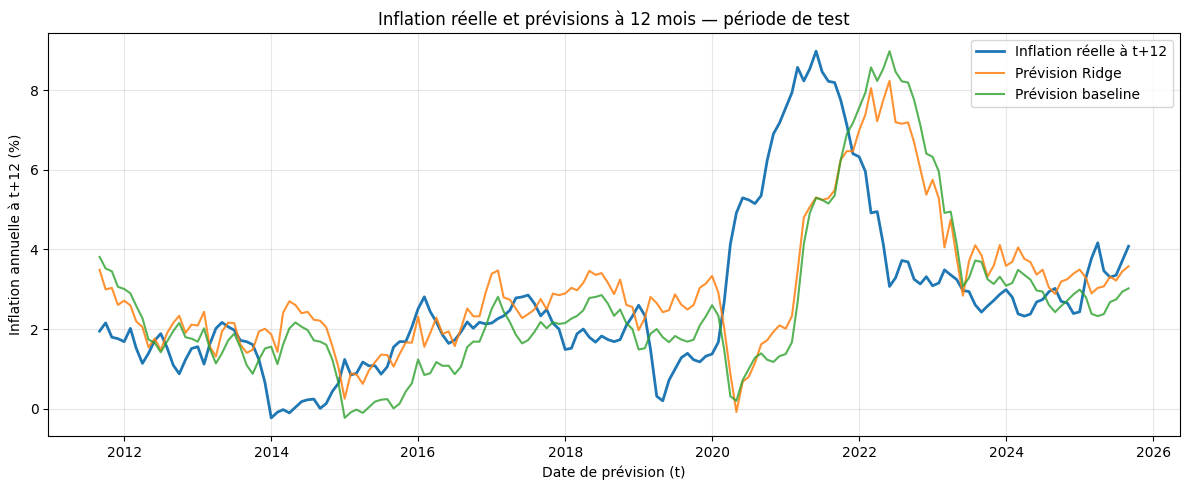

In [13]:
# Comparer les valeurs réelles, Ridge et baseline sur la période de test
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test.values, label="Inflation réelle à t+12", linewidth=2)
plt.plot(y_test.index, y_pred, label="Prévision Ridge", alpha=0.85)
plt.plot(y_test.index, y_baseline.values, label="Prévision baseline", alpha=0.8)
plt.title("Inflation réelle et prévisions à 12 mois — période de test")
plt.xlabel("Date de prévision (t)")
plt.ylabel("Inflation annuelle à t+12 (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

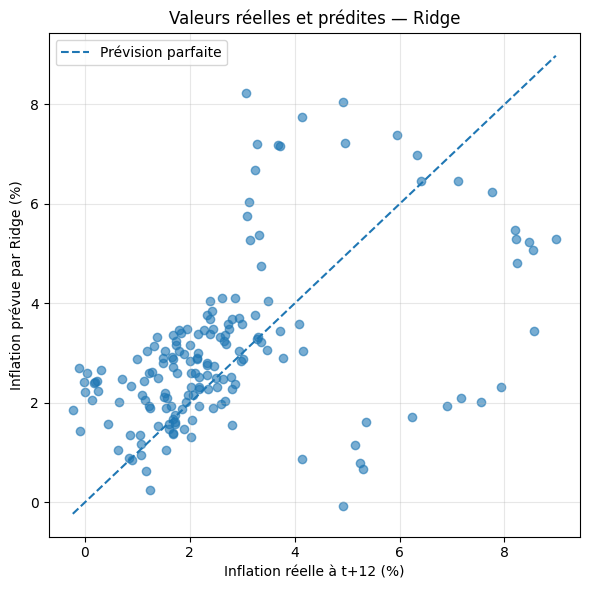

In [14]:
# Nuage réel / prédit pour Ridge
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
limites = [
    min(float(y_test.min()), float(np.min(y_pred))),
    max(float(y_test.max()), float(np.max(y_pred)))
]
plt.plot(limites, limites, linestyle="--", label="Prévision parfaite")
plt.xlabel("Inflation réelle à t+12 (%)")
plt.ylabel("Inflation prévue par Ridge (%)")
plt.title("Valeurs réelles et prédites — Ridge")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Importance des variables (coefficients Ridge)

Les coefficients sont calculés sur les variables standardisées. Leur signe indique le sens de l’association dans le modèle, toutes choses égales par ailleurs. Ils ne prouvent pas un lien de causalité.

,Variable,Coefficient_standardise
0,inflation_t,3.7312
1,inflation_lag1,-1.5876
3,inflation_lag6,-0.6108
2,inflation_lag3,0.4445
5,chomage_lag1,-0.1953
4,inflation_lag12,0.1128
6,taux_directeur_lag1,0.0731


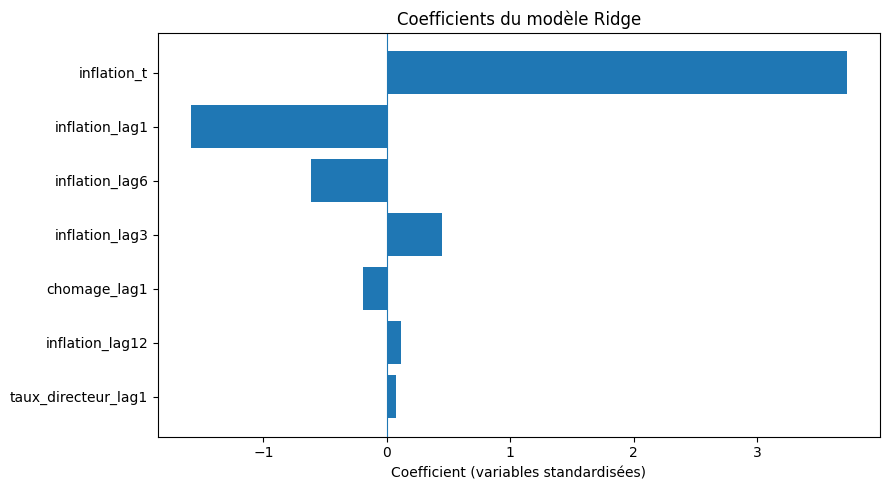

In [15]:
ridge_estimator = model.named_steps["ridge"]
coefficients = pd.DataFrame({
    "Variable": features,
    "Coefficient_standardise": ridge_estimator.coef_
}).sort_values("Coefficient_standardise", key=lambda s: s.abs(), ascending=False)

display(coefficients.round(4))

plt.figure(figsize=(9, 5))
plt.barh(coefficients["Variable"], coefficients["Coefficient_standardise"])
plt.axvline(0, linewidth=0.8)
plt.title("Coefficients du modèle Ridge")
plt.xlabel("Coefficient (variables standardisées)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 11. Résultats détaillés et exportation

Le fichier CSV contient la date de prévision, la date cible, l’inflation réelle à t+12, la prévision Ridge et la prévision baseline.

In [16]:
resultats = pd.DataFrame(index=y_test.index)
resultats.index.name = "date_prevision"
resultats["date_cible"] = model_data.loc[y_test.index, "date_cible"]
resultats["inflation_reelle_t_plus_12"] = y_test
resultats["prevision_ridge"] = y_pred
resultats["prevision_baseline"] = y_baseline

display(resultats.head(10).round(3))
resultats.to_csv("resultats_inflation_12_mois.csv", index=True)
print("Fichier créé : resultats_inflation_12_mois.csv")

,date_cible,inflation_reelle_t_plus_12,prevision_ridge,prevision_baseline
date_prevision,,,,
2011-09-01,2012-09-01,1.950,3.488,3.813
2011-10-01,2012-10-01,2.156,2.997,3.522
2011-11-01,2012-11-01,1.796,3.034,3.451
2011-12-01,2012-12-01,1.760,2.607,3.062
2012-01-01,2013-01-01,1.684,2.714,3.009
2012-02-01,2013-02-01,2.018,2.595,2.898
2012-03-01,2013-03-01,1.519,2.195,2.583
2012-04-01,2013-04-01,1.139,2.051,2.273
2012-05-01,2013-05-01,1.390,1.541,1.738


Fichier créé : resultats_inflation_12_mois.csv


## 12. Conclusion automatique à compléter avec l’analyse

La cellule suivante résume les performances calculées. Il faut ensuite rédiger une interprétation personnelle : expliquer si Ridge dépasse le baseline, commenter les limites et éviter de présenter une association statistique comme une causalité.

In [17]:
print("CONCLUSION DES RÉSULTATS")
print("------------------------")
print(f"RMSE baseline : {metriques_baseline['RMSE']:.3f}")
print(f"RMSE Ridge    : {metriques_ridge['RMSE']:.3f}")
print(f"MAE baseline  : {metriques_baseline['MAE']:.3f}")
print(f"MAE Ridge     : {metriques_ridge['MAE']:.3f}")
print(f"R² Ridge      : {metriques_ridge['R2']:.3f}")
print(f"Évolution du RMSE : {reduction_rmse:.2f} % par rapport au baseline")

if reduction_rmse >= 10:
    verdict = "Ridge atteint l'objectif d'une réduction du RMSE d'au moins 10 %."
elif reduction_rmse > 0:
    verdict = "Ridge améliore le baseline, mais n'atteint pas la réduction de 10 %."
else:
    verdict = "Ridge ne surpasse pas le baseline sur le RMSE."

print("\n", verdict)
print("\nLimites à rappeler :")
print("- Les données concernent les États-Unis et non le Maroc.")
print("- Les résultats dépendent de la période de test choisie.")
print("- Les relations statistiques ne démontrent pas une causalité.")
print("- Les séries macroéconomiques peuvent être révisées et publiées avec retard.")

CONCLUSION DES RÉSULTATS
------------------------
RMSE baseline : 2.080
RMSE Ridge    : 1.924
MAE baseline  : 1.466
MAE Ridge     : 1.384
R² Ridge      : 0.067
Évolution du RMSE : 7.49 % par rapport au baseline

 Ridge améliore le baseline, mais n'atteint pas la réduction de 10 %.

Limites à rappeler :
- Les données concernent les États-Unis et non le Maroc.
- Les résultats dépendent de la période de test choisie.
- Les relations statistiques ne démontrent pas une causalité.
- Les séries macroéconomiques peuvent être révisées et publiées avec retard.


## 13. Sources des données

- FRED — CPIAUCSL : https://fred.stlouisfed.org/series/CPIAUCSL
- FRED — UNRATE : https://fred.stlouisfed.org/series/UNRATE
- FRED — FEDFUNDS : https://fred.stlouisfed.org/series/FEDFUNDS
- Documentation pandas-datareader : https://pandas-datareader.readthedocs.io/
- Documentation scikit-learn — Ridge : https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html

**Reproductibilité :** les données sont téléchargées au moment de l’exécution. La dernière date disponible peut donc changer selon la date d’exécution.